# Ames Housing — Model Evaluation

Compare regression models using a held-out validation set.

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn

# Locate the project root from this notebook's working directory
candidates = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd().parent.parent,
]

project_root = next(
    (p for p in candidates
     if (p / "data" / "raw" / "ames_housing" / "train.csv").exists()),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Could not find data/raw/ames_housing/train.csv. "
        "Check that the dataset is in the project folder."
    )

data_path = project_root / "data" / "raw" / "ames_housing" / "train.csv"
df = pd.read_csv(data_path)

print("Dataset:", data_path)
print("Shape:", df.shape)
print("Target present:", "SalePrice" in df.columns)
print("scikit-learn version:", sklearn.__version__)
display(df.head())

Dataset: C:\Users\Aditya Khurana\Desktop\Idc409-Group18-House-Prediction\data\raw\ames_housing\train.csv
Shape: (1460, 81)
Target present: True
scikit-learn version: 1.9.1


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
from sklearn.model_selection import train_test_split

# Separate the target from the input features
if "SalePrice" not in df.columns:
    raise ValueError("SalePrice column is missing from the dataset.")

X = df.drop(columns=["SalePrice", "Id"], errors="ignore")
y = df["SalePrice"]

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

# Split before fitting any preprocessing or models
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_valid))
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Missing target values:", y.isna().sum())

Training rows: 1168
Validation rows: 292
Numeric features: 36
Categorical features: 43
Missing target values: 0


C:\Users\Aditya Khurana\AppData\Local\Temp\ipykernel_22936\1767777087.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessor configured to output dense data.")

Preprocessor configured to output dense data.


In [11]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Use the same preprocessing and validation split for every model
models = {
    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=200,
        learning_rate=0.05,
        max_leaf_nodes=20,
        l2_regularization=1.0,
        random_state=42
    )
}

results = []
fitted_models = {}

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_valid)

    rmse = np.sqrt(mean_squared_error(y_valid, predictions))
    mae = mean_absolute_error(y_valid, predictions)
    r2 = r2_score(y_valid, predictions)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    fitted_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)

display(results_df.round(3))
print("Lowest validation RMSE:", results_df.iloc[0]["Model"])

,Model,RMSE,MAE,R2
0,HistGradientBoosting,28821.195,16668.037,0.892
1,Random Forest,28845.871,17468.107,0.892
2,Linear Regression,29475.525,18287.846,0.887


Lowest validation RMSE: HistGradientBoosting


### Initial Model Evaluation

Three regression models were evaluated using an 80/20 train-validation split with `random_state=42`. All models used the same preprocessing pipeline, with missing-value imputation, numeric scaling, and categorical one-hot encoding fitted within each training pipeline.

| Model | RMSE | MAE | R² |
|---|---:|---:|---:|
| HistGradientBoosting | 28,821.195 | 16,668.037 | 0.892 |
| Random Forest | 28,845.871 | 17,468.107 | 0.892 |
| Linear Regression | 29,475.525 | 18,287.846 | 0.887 |

HistGradientBoosting achieved the lowest validation RMSE and MAE in this initial comparison. Its performance was very close to Random Forest, so further validation is required before final model selection.

Linear Regression provided a baseline, but had higher validation errors than the two tree-based models.

These results are preliminary and depend on a single random train-validation split. The validation set has not been used for final model fitting.


In [12]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []

for name, estimator in models.items():
    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])

    scores = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        n_jobs=1
    )

    cv_results.append({
        "Model": name,
        "Mean CV RMSE": -scores["test_rmse"].mean(),
        "Std CV RMSE": scores["test_rmse"].std(),
        "Mean CV MAE": -scores["test_mae"].mean(),
        "Mean CV R2": scores["test_r2"].mean()
    })

cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values("Mean CV RMSE")
    .reset_index(drop=True)
)

display(cv_results_df.round(3))

,Model,Mean CV RMSE,Std CV RMSE,Mean CV MAE,Mean CV R2
0,HistGradientBoosting,28378.719,4982.468,16280.983,0.863
1,Random Forest,30565.269,4942.781,18226.647,0.841
2,Linear Regression,36397.202,7544.971,19621.958,0.770


Selected candidate: HistGradientBoosting
Validation RMSE: $28,821.19
Validation MAE:  $16,668.04


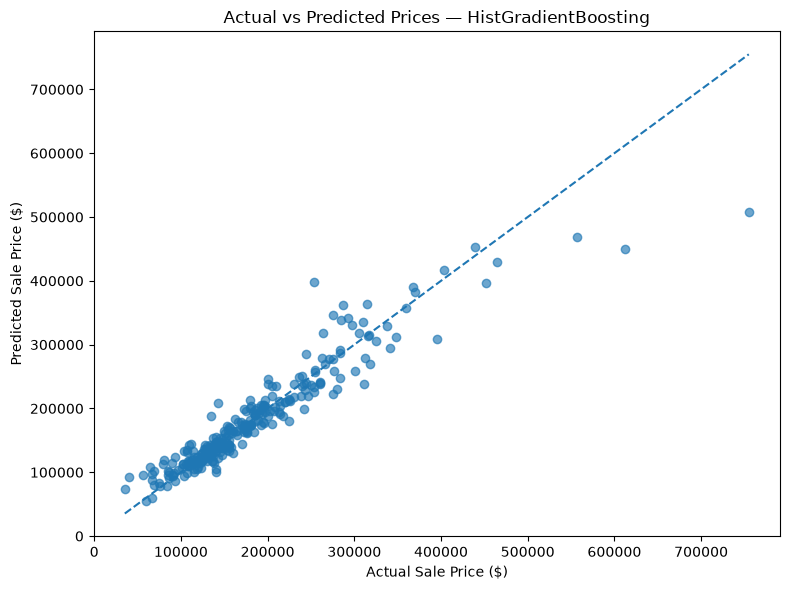

In [13]:
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Get the best model from the initial validation comparison
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

# Predict prices for the untouched validation set
y_pred = best_model.predict(X_valid)

# Calculate validation metrics
rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
mae = mean_absolute_error(y_valid, y_pred)

print("Selected candidate:", best_model_name)
print(f"Validation RMSE: ${rmse:,.2f}")
print(f"Validation MAE:  ${mae:,.2f}")

# Actual prices vs predicted prices
plt.figure(figsize=(8, 6))
plt.scatter(y_valid, y_pred, alpha=0.65)

# Reference line: perfect predictions fall on this line
price_min = min(y_valid.min(), y_pred.min())
price_max = max(y_valid.max(), y_pred.max())
plt.plot(
    [price_min, price_max],
    [price_min, price_max],
    linestyle="--"
)

plt.xlabel("Actual Sale Price ($)")
plt.ylabel("Predicted Sale Price ($)")
plt.title(f"Actual vs Predicted Prices — {best_model_name}")
plt.tight_layout()
plt.show()

In [15]:
# Recreate predictions and error analysis
best_model_name = results_df.iloc[0]["Model"]
best_model = fitted_models[best_model_name]

y_pred = best_model.predict(X_valid)

error_analysis = pd.DataFrame({
    "ActualPrice": y_valid,
    "PredictedPrice": y_pred
})

error_analysis["AbsoluteError"] = (
    error_analysis["ActualPrice"] - error_analysis["PredictedPrice"]
).abs()

error_analysis["SignedError"] = (
    error_analysis["PredictedPrice"] - error_analysis["ActualPrice"]
)

# Group errors by actual sale price
error_analysis["PriceRange"] = pd.cut(
    error_analysis["ActualPrice"],
    bins=[0, 100000, 200000, 300000, 400000, float("inf")],
    labels=["$0–100k", "$100–200k", "$200–300k", "$300–400k", "$400k+"],
    include_lowest=True
)

error_by_range = (
    error_analysis.groupby("PriceRange", observed=False)
    .agg(
        Houses=("ActualPrice", "size"),
        MeanAbsoluteError=("AbsoluteError", "mean"),
        MeanActualPrice=("ActualPrice", "mean"),
        MeanPredictedPrice=("PredictedPrice", "mean")
    )
    .round(2)
)

display(error_by_range)

,Houses,MeanAbsoluteError,MeanActualPrice,MeanPredictedPrice
PriceRange,,,,
$0–100k,26,19354.56,76091.35,93435.51
$100–200k,184,9879.10,145749.93,146456.39
$200–300k,58,24174.15,243004.60,244761.28
$300–400k,17,30937.94,332272.18,316082.10
$400k+,7,88292.66,525995.43,445940.99


In [16]:
display(
    error_analysis
    .sort_values("ActualPrice")
    [["ActualPrice", "PredictedPrice", "AbsoluteError"]]
    .head(10)
    .round(2)
)

,ActualPrice,PredictedPrice,AbsoluteError
916,35311,74248.60,38937.60
30,40000,93035.83,53035.83
812,55993,95672.04,39679.04
636,60000,55216.06,4783.94
1432,64500,107644.54,43144.54
874,66500,96735.46,30235.46
620,67000,59552.83,7447.17
398,67000,87364.14,20364.14
1279,68400,102063.63,33663.63
29,68500,80036.24,11536.24


In [17]:
# Show the raw values with clear formatting
print(
    error_analysis
    .sort_values("ActualPrice")
    [["ActualPrice", "PredictedPrice", "AbsoluteError"]]
    .head(10)
    .to_string(index=False, formatters={
        "ActualPrice": "${:,.2f}".format,
        "PredictedPrice": "${:,.2f}".format,
        "AbsoluteError": "${:,.2f}".format
    })
)

ActualPrice PredictedPrice AbsoluteError
 $35,311.00     $74,248.60    $38,937.60
 $40,000.00     $93,035.83    $53,035.83
 $55,993.00     $95,672.04    $39,679.04
 $60,000.00     $55,216.06     $4,783.94
 $64,500.00    $107,644.54    $43,144.54
 $66,500.00     $96,735.46    $30,235.46
 $67,000.00     $59,552.83     $7,447.17
 $67,000.00     $87,364.14    $20,364.14
 $68,400.00    $102,063.63    $33,663.63
 $68,500.00     $80,036.24    $11,536.24


In [18]:
# Positive SignedError = overprediction
# Negative SignedError = underprediction

bias_by_range = (
    error_analysis.groupby("PriceRange", observed=False)
    .agg(
        Houses=("ActualPrice", "size"),
        MeanSignedError=("SignedError", "mean"),
        MedianAbsoluteError=("AbsoluteError", "median")
    )
    .round(2)
)

display(bias_by_range)

,Houses,MeanSignedError,MedianAbsoluteError
PriceRange,,,
$0–100k,26,17344.17,13203.80
$100–200k,184,706.45,7267.57
$200–300k,58,1756.67,17468.37
$300–400k,17,-16190.08,26067.54
$400k+,7,-80054.44,56046.87


### Prediction Error Analysis

Prediction errors were examined by actual sale-price range on the held-out validation set.

The model showed a tendency to overpredict lower-priced houses and underpredict higher-priced houses. The highest-price group contained only seven validation houses, so its error estimates are less stable and should be interpreted cautiously.

HistGradientBoosting remains the leading candidate based on the initial validation comparison and five-fold cross-validation. Its performance is not uniform across all price ranges, so these limitations should be considered when reporting the results.

No validation records were removed based on their prediction errors. The validation set remains separate from model fitting.


In [19]:
print(bias_by_range.to_string())

            Houses  MeanSignedError  MedianAbsoluteError
PriceRange                                              
$0–100k         26         17344.17             13203.80
$100–200k      184           706.45              7267.57
$200–300k       58          1756.67             17468.37
$300–400k       17        -16190.08             26067.54
$400k+           7        -80054.44             56046.87


## Conclusion and Limitations

Three regression models were compared using a fixed 80/20 train-validation split and five-fold cross-validation on the training portion.

HistGradientBoosting achieved the best initial validation results (RMSE: \\\$28,821.20; MAE: \\$16,668.04; R²: 0.892) and the best mean cross-validation results (RMSE: \\\$28,378.72; MAE: \\\$16,280.98; R²: 0.863). It is therefore the leading candidate among the three models evaluated.

Error analysis showed that prediction performance varies by price range. The model overpredicted lower-priced houses on average and underpredicted houses priced above \$300,000 on average. The \\$400,000+ group contained only seven validation examples, so this estimate is uncertain.

These results are preliminary and reflect one train-validation split. The selected pipeline should be evaluated on the held-out validation set only after model selection is complete. No validation records were removed based on prediction errors.
